Example 10: Blend Viscosity from Spectra (Static Mixture Model)

A port of ``asphalt_blending.py`` onto :class:`kipetax.MixtureModel`. It is the
same non-additive interaction motif as the rest of this project, with no time
axis: property prediction from a blend rather than kinetics from a time series.

Each of four bitumen components has an FTIR-like spectrum and a viscosity.
Blending mixes both NON-additively, and one ``w_i w_j`` object covers both
levels:

    spectrum:   S_blend  = sum_i w_i S_i     + sum_{i<j} w_i w_j Gamma_ij
    viscosity:  ln eta   = sum_i w_i ln eta_i + sum_{i<j} w_i w_j d_ij

``Gamma_ij`` is an interaction band that appears only for an incompatible pair
(here components 0 and 3); ``d_ij`` is the classic Grunberg-Nissan viscosity
interaction parameter. Both models are linear in their parameters given the
blend fractions and share one design matrix ``[w_i | w_i w_j]``, so calibration
is two least-squares fits and prediction of a new recipe is a matrix product.

Three things are shown. Calibration recovers the component properties AND the
interaction terms. On held-out blends the interaction-aware viscosity model beats
the additive-only model, most on the incompatible-pair blends where the buried
interaction does the most damage. And the inverse works: infer composition from a
measured blend spectrum, push it through the viscosity law, and predict viscosity
from a spectrum alone.

NOTE: all data here is SYNTHETIC, generated by the model below.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import os

## Setup: helper functions and synthetic-data generators

These are lifted verbatim from the example script (`kipetax/examples/Ex_10_asphalt_blending.py`).

In [2]:
from itertools import combinations

import numpy as np

from kipetax import MixtureModel

NU = np.linspace(700.0, 1800.0, 220)
NCOMP = 4
PAIRS = list(combinations(range(NCOMP), 2))
IPAIR_03 = PAIRS.index((0, 3))

BANDS = [1700, 1600, 1460, 1376, 1030, 870, 812, 750]
BW = [18, 16, 14, 12, 20, 10, 10, 10]
AMP = np.array([
    [0.60, 0.90, 0.70, 0.40, 0.50, 0.50, 0.40, 0.30],   # 0: aged, aromatic
    [0.10, 0.40, 1.00, 0.70, 0.20, 0.20, 0.15, 0.10],   # 1: aliphatic, soft
    [0.20, 0.60, 0.80, 0.50, 0.40, 0.35, 0.30, 0.20],   # 2: mid
    [0.30, 0.85, 0.60, 0.35, 0.90, 0.50, 0.45, 0.35],   # 3: high-sulfur, stiff
])

def lorentz(nu, c, w, a):
    return a * w ** 2 / ((nu - c) ** 2 + w ** 2)

def comp_spectra():
    S = np.zeros((NCOMP, NU.size))
    for k in range(NCOMP):
        for (c, w, a) in zip(BANDS, BW, AMP[k]):
            S[k] += lorentz(NU, c, w, a)
    return S

def true_params():
    S = comp_spectra()
    Gamma = np.zeros((len(PAIRS), NU.size))
    Gamma[IPAIR_03] = lorentz(NU, 1560.0, 18.0, 0.55)    # interaction band
    ln_eta = np.log(np.array([150.0, 400.0, 900.0, 2500.0]))
    d = np.zeros(len(PAIRS))
    d[IPAIR_03] = 2.0                                    # Grunberg-Nissan d_03
    return S, Gamma, ln_eta, d

def make_blends(rng):
    train = [np.eye(NCOMP)]
    for (i, j) in PAIRS:
        for f in (0.3, 0.5, 0.7):
            w = np.zeros(NCOMP); w[i] = f; w[j] = 1 - f
            train.append(w[None, :])
    train.append(rng.dirichlet(np.ones(NCOMP), size=6))
    W_train = np.vstack(train)

    test = []
    for f in (0.2, 0.4, 0.5, 0.6, 0.8):                  # incompatible pair 0-3
        w = np.zeros(NCOMP); w[0] = f; w[3] = 1 - f
        test.append(w)
    for (i, j) in [(0, 1), (0, 2), (1, 2), (1, 3), (2, 3)]:
        w = np.zeros(NCOMP); w[i] = 0.5; w[j] = 0.5
        test.append(w)
    return W_train, np.array(test)

def has_03(W):
    return (W[:, 0] > 1e-6) & (W[:, 3] > 1e-6)

## Run the analysis

In [3]:
rng = np.random.default_rng(0)
S_true, Gamma_true, ln_eta_true, d_true = true_params()
W_tr, W_te = make_blends(rng)

In [4]:
# Generate synthetic measurements from the interaction-aware truth.
spec_truth = MixtureModel(NCOMP, interaction=True)
spec_truth.component_props = S_true
spec_truth.interaction_props = Gamma_true
spec_truth._coef = np.vstack([S_true, Gamma_true])
visc_truth = MixtureModel(NCOMP, interaction=True)
visc_truth._coef = np.concatenate([ln_eta_true, d_true])
visc_truth.component_props = ln_eta_true
visc_truth.interaction_props = d_true

In [5]:
D_tr = spec_truth.predict(W_tr) + 0.01 * rng.standard_normal((W_tr.shape[0], NU.size))
lnv_tr = visc_truth.predict(W_tr) + 0.03 * rng.standard_normal(W_tr.shape[0])
eta_te_true = np.exp(visc_truth.predict(W_te))

In [6]:
# Calibrate: additive-only vs interaction-aware, each fit by least squares.
spec_int = MixtureModel(NCOMP, interaction=True).fit(W_tr, D_tr)
visc_add = MixtureModel(NCOMP, interaction=False).fit(W_tr, lnv_tr)
visc_int = MixtureModel(NCOMP, interaction=True).fit(W_tr, lnv_tr)

In [7]:
lnv_add = visc_add.predict(W_te)
lnv_int = visc_int.predict(W_te)
m03 = has_03(W_te)

In [8]:
def rel(pred_ln):
    return np.abs(np.exp(pred_ln) - eta_te_true) / eta_te_true

In [9]:
print("=" * 72)
print("ASPHALT BLENDING: predict blend viscosity from spectra")
print("(SYNTHETIC, illustrative data, not experimental measurements.)")
print("=" * 72)
print(f"\nComponents: {NCOMP}   training blends: {W_tr.shape[0]}   "
      f"held-out blends: {W_te.shape[0]}")
print(f"Incompatible pair: components 0 and 3 (true d_03 = {d_true[IPAIR_03]:.2f}, "
      f"interaction band at 1560 cm^-1)")

ASPHALT BLENDING: predict blend viscosity from spectra
(SYNTHETIC, illustrative data, not experimental measurements.)

Components: 4   training blends: 28   held-out blends: 10
Incompatible pair: components 0 and 3 (true d_03 = 2.00, interaction band at 1560 cm^-1)


In [10]:
print("\nHeld-out viscosity prediction (mean relative error):")
print(f"  additive-only model     : all {rel(lnv_add).mean():6.1%}   "
      f"blends with 0&3 {rel(lnv_add)[m03].mean():6.1%}")
print(f"  interaction-aware model : all {rel(lnv_int).mean():6.1%}   "
      f"blends with 0&3 {rel(lnv_int)[m03].mean():6.1%}")


Held-out viscosity prediction (mean relative error):
  additive-only model     : all  13.1%   blends with 0&3  18.9%
  interaction-aware model : all   0.6%   blends with 0&3   0.2%


In [11]:
d03_fit = visc_int.interaction_parameter(0, 3)
print(f"\nRecovered interaction parameter d_03 = {d03_fit:.2f} (true 2.00); "
      f"the additive model has no such term and buries it in the component "
      f"viscosities.")


Recovered interaction parameter d_03 = 1.96 (true 2.00); the additive model has no such term and buries it in the component viscosities.


In [12]:
# Inverse: spectrum -> composition (via the spectral model) -> viscosity.
eta_from_spec = []
for k in range(W_te.shape[0]):
    w = spec_int.infer_composition(spec_truth.predict(W_te[k]))
    eta_from_spec.append(np.exp(visc_int.predict(w))[0])
eta_from_spec = np.array(eta_from_spec)
inv_err = np.abs(eta_from_spec - eta_te_true) / eta_te_true
print(f"\nInverse (spectrum -> composition -> viscosity): mean rel. error "
      f"{inv_err.mean():.1%}")
print("  -> viscosity predicted from a measured blend spectrum alone.")
print("=" * 72)
visc_int


Inverse (spectrum -> composition -> viscosity): mean rel. error 2.5%
  -> viscosity predicted from a measured blend spectrum alone.


## Visualization

Persistent figures: held-out viscosity parity (additive vs interaction-aware), the recovered interaction band, the inverse spectrum-to-viscosity prediction, and the error breakdown.

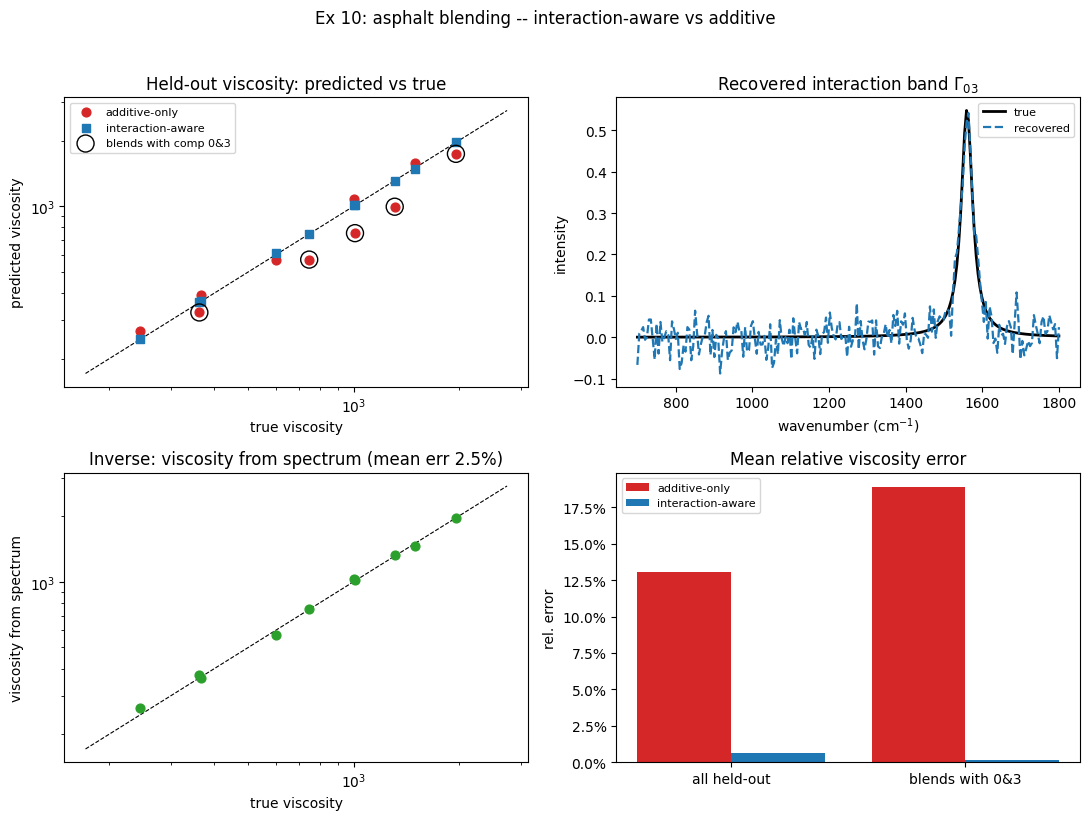

In [13]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

eta_add = np.exp(lnv_add)
eta_int = np.exp(lnv_int)

fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# (a) Held-out viscosity parity: additive-only vs interaction-aware.
lim = [eta_te_true.min() * 0.7, eta_te_true.max() * 1.4]
ax[0, 0].plot(lim, lim, 'k--', lw=0.8, zorder=0)
ax[0, 0].scatter(eta_te_true, eta_add, s=40, c='C3', marker='o',
                 label='additive-only')
ax[0, 0].scatter(eta_te_true, eta_int, s=40, c='C0', marker='s',
                 label='interaction-aware')
ax[0, 0].scatter(eta_te_true[m03], eta_add[m03], s=150, facecolors='none',
                 edgecolors='k', lw=1.0, label='blends with comp 0&3')
ax[0, 0].set(xscale='log', yscale='log',
             title='Held-out viscosity: predicted vs true',
             xlabel='true viscosity', ylabel='predicted viscosity')
ax[0, 0].legend(fontsize=8)

# (b) Recovered interaction band for the incompatible 0&3 pair.
ax[0, 1].plot(NU, Gamma_true[IPAIR_03], 'k-', lw=2, label='true')
ax[0, 1].plot(NU, spec_int.interaction_props[IPAIR_03], 'C0--', lw=1.6,
              label='recovered')
ax[0, 1].set(title=r'Recovered interaction band $\Gamma_{03}$',
             xlabel='wavenumber (cm$^{-1}$)', ylabel='intensity')
ax[0, 1].legend(fontsize=8)

# (c) Inverse: viscosity predicted from a measured spectrum alone.
ax[1, 0].plot(lim, lim, 'k--', lw=0.8, zorder=0)
ax[1, 0].scatter(eta_te_true, eta_from_spec, s=40, c='C2')
ax[1, 0].set(xscale='log', yscale='log',
             title=f'Inverse: viscosity from spectrum (mean err {inv_err.mean():.1%})',
             xlabel='true viscosity', ylabel='viscosity from spectrum')

# (d) Mean relative error: additive vs interaction, all vs 0&3 blends.
groups = ['all held-out', 'blends with 0&3']
add_err = [rel(lnv_add).mean(), rel(lnv_add)[m03].mean()]
int_err = [rel(lnv_int).mean(), rel(lnv_int)[m03].mean()]
x = np.arange(len(groups))
ax[1, 1].bar(x - 0.2, add_err, 0.4, color='C3', label='additive-only')
ax[1, 1].bar(x + 0.2, int_err, 0.4, color='C0', label='interaction-aware')
ax[1, 1].set_xticks(x)
ax[1, 1].set_xticklabels(groups)
ax[1, 1].yaxis.set_major_formatter(PercentFormatter(1.0))
ax[1, 1].set(title='Mean relative viscosity error', ylabel='rel. error')
ax[1, 1].legend(fontsize=8)

fig.suptitle('Ex 10: asphalt blending -- interaction-aware vs additive', y=1.02)
fig.tight_layout()